# Data Preprocessing

### Objective

This notebook preprocesses and prepares the NIH Chest X-ray images for deep learning experiments uding PyTorch. 

The original NIH X-ray images are 1024x1024 grayscale JPEG images. For compatibility with ImageNet-pretrained ResNet18, the images will be resized to 224x224 pixels, converted to 3 channels, and normalised using ImageNet statistics.

The preprocessing pipeline will be implemented as reusable Python code so that it can be shared across subsequent model experiments. 

### Planned Workflow
1. Define image transformations
2. Implement a custom PyTorch Dataset
3. Create training, validation, and test DataLoaders
4. Inspect and verify the transformed images
5. Check tensor dimensions, labels and reproducibility

## 01. Define image transformations

### 1.1 Inspect an original image

Understand 1 original CXR image's initial dimensions, colour mode, and pixel intensity range

In [2]:
from pathlib import Path
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision import transforms

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Locate project and dataset
cwd = Path.cwd().resolve()
PROJECT_DIR = next((path for path in [cwd, *cwd.parents]
    if path.name == "transfer-learning-resnet"
    and (path.parent / "data" / "processed" / "mlp_dataset.csv").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Could not locate project directory")
DATA_DIR = PROJECT_DIR.parent / "data"
IMAGE_DIR = DATA_DIR / "raw" / "images"
CSV_PATH = DATA_DIR / "processed" / "mlp_dataset.csv"
df = pd.read_csv(CSV_PATH)

# Select 1 reproducible sample for visualization
sample_row = df.sample(n=1, random_state=SEED).iloc[0]
sample_image_path = IMAGE_DIR / sample_row["Image Index"]

# Load original image
original_image = Image.open(sample_image_path)
print("Image:", sample_row["Image Index"])
print("Label:", sample_row["Label"])
print("Original dimensions:", original_image.size)
print("Original mode:", original_image.mode)
print("Pixel intensity range:", np.array(original_image).min(), "to", np.array(original_image).max())

Image: 00000425_001.png
Label: 0
Original dimensions: (1024, 1024)
Original mode: L
Pixel intensity range: 0 to 251


### 1.2 Define preprocessing transformations

The original grayscale images will be sized to 224x224 pixels and converted to 3 channels to meet ResNet18's input requirements.

Pixel intensities will first be converted into tensors with values between 0 and 1. ImageNet normalisation will then be applied to align the input format with the convention used when training the pretrained ResNet18 weights.

In [4]:
# ImageNet normalisation parameters
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Define deterministic preprocessing
preprocess_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),  # Convert to 3 channels
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)])
print(preprocess_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    Grayscale(num_output_channels=3)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### 1.3 Apply and inspect transformations

Apply the preprocessing pipeline to the sample image and inspect the resulting tensor dimensions and value range to verify that image is compatible with expected ResNet18 input format.

In [5]:
# Apply preprocessing to sample image
transformed_image = preprocess_transform(original_image)
print("Transformed tensor shape:", transformed_image.shape)
print("Transformed tensor dtype:", transformed_image.dtype)
print("Min pixel value:", transformed_image.min().item())
print("Max pixel value:", transformed_image.max().item())

Transformed tensor shape: torch.Size([3, 224, 224])
Transformed tensor dtype: torch.float32
Min pixel value: -2.1179039478302
Max pixel value: 2.5005664825439453


### 1.4 Visualise preprocessing result

For visualisation, normalisation on pixel values will be reversed. 

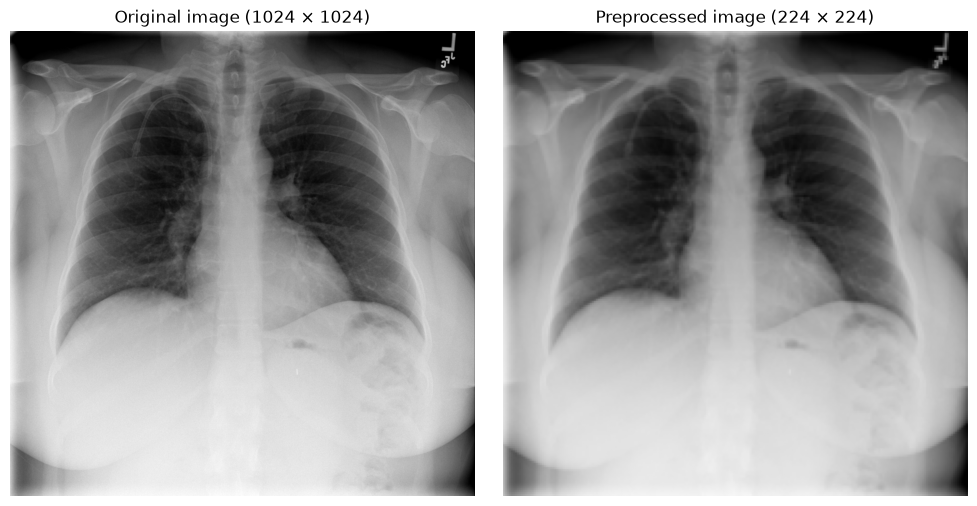

In [6]:
# Reverse normalisation for visualisation
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

display_tensor = transformed_image * std + mean

# Convert to NumPy for plotting
display_image = display_tensor[0].numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image, cmap="gray")
axes[0].set_title("Original image (1024 × 1024)")
axes[0].axis("off")

axes[1].imshow(display_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Preprocessed image (224 × 224)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### 1.5 Verify that python script works

Python script (transforms.py) in src/ is created to transform dataset, using pipeline defined earlier. The next cell helps verify that the script works. 

In [7]:
import sys

# Add project root to Python's import path
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from src.transforms import get_preprocessing_transform

# Load reusable transformation
preprocess_transform = get_preprocessing_transform()
# Apply to sample image
transformed_script_image = preprocess_transform(original_image)
# Verify identical output
print("Transformation outputs match:", torch.allclose(transformed_image, transformed_script_image))

Transformation outputs match: True


## 02. Implement a custom PyTorch Dataset

Currently, original images are stored in data/raw/images/. Labels and patient IDs are stored in mlp_dataset.csv. Preprocessing transformations are stored in src/transforms.py. 

The custom Dataset class will connect all 3 to identify an image using its filename, load that image, apply the preprocessing transformation, retrieve its label and patient ID, and return these together as 1 data sample.

Dataset class is within python script "data_loader.py" under src/.

### 2.1 Create training DataLoader (and test Dataset class in data_loader.py)

In [9]:
from src.data_loader import ChestXrayDataset

# Create training dataset
train_dataset = ChestXrayDataset(
    csv_path=CSV_PATH,
    image_dir=IMAGE_DIR,
    transform=preprocess_transform,
    split="train")
print("Training dataset size:", len(train_dataset)) 

# Retrieve first sample
image, label, patient_id = train_dataset[0]
print("Image tensor shape:", image.shape)
print("Label:", label)
print("Patient ID:", patient_id)
print("Image tensor dtype:", image.dtype)
print("Label type:", type(label))

Training dataset size: 2208
Image tensor shape: torch.Size([3, 224, 224])
Label: 0
Patient ID: 2
Image tensor dtype: torch.float32
Label type: <class 'int'>


### 2.2 Create validation and test DataLoaders

In [10]:
valid_dataset = ChestXrayDataset(
    csv_path=CSV_PATH,
    image_dir=IMAGE_DIR,
    transform=preprocess_transform,
    split="val")

test_dataset = ChestXrayDataset(
    csv_path=CSV_PATH,
    image_dir=IMAGE_DIR,
    transform=preprocess_transform,
    split="test")

print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))
print("Total images:", len(train_dataset) + len(valid_dataset) + len(test_dataset))

Validation images: 554
Test images: 479
Total images: 3241


## 03. Inspect and verify the transformed images, tensor dimensions, labels, and reproducibility

In [14]:
for name, dataset in [
    ("Train", train_dataset),
    ("Validation", valid_dataset),
    ("Test", test_dataset)
]:
    image, label, patient_id = dataset[0]

    print(
        f"{name}: shape={image.shape}, "
        f"label={label}, "
        f"patient_id={patient_id}, "
        f"dtype={image.dtype}"
    )

Train: shape=torch.Size([3, 224, 224]), label=0, patient_id=2, dtype=torch.float32
Validation: shape=torch.Size([3, 224, 224]), label=1, patient_id=1, dtype=torch.float32
Test: shape=torch.Size([3, 224, 224]), label=1, patient_id=13, dtype=torch.float32


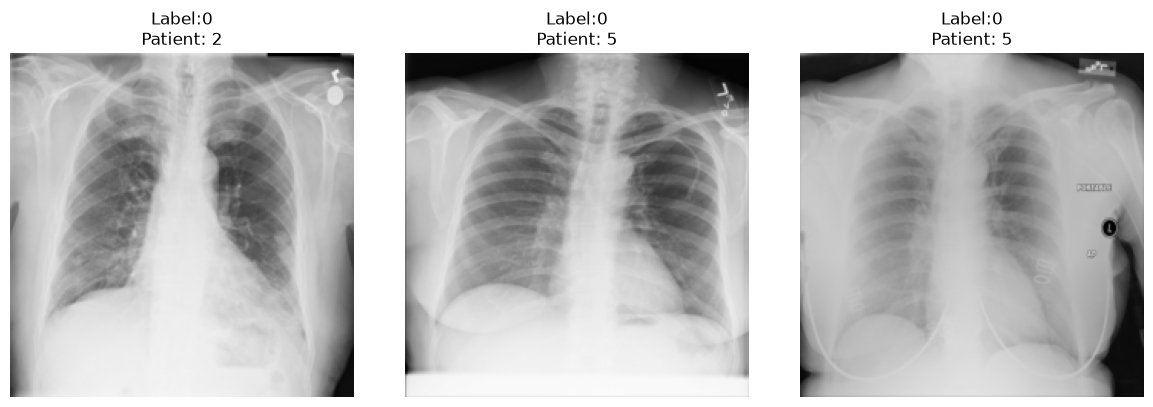

In [15]:
def denormalise(image_tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return image_tensor * std + mean

fig, axes = plt.subplots(1, 3, figsize=(12,4))
for i, ax in enumerate(axes):
    image, label, patient_id = train_dataset[i]
    image_display = denormalise(image).permute(1, 2, 0)
    ax.imshow(image_display, cmap="gray")
    ax.set_title(f"Label:{label}\nPatient: {patient_id}")
    ax.axis("off")
plt.tight_layout()
plt.show()    

In [20]:
# Confirm 3 grayscale channels contain identical values
# Retrieve the image before normalisation
row = train_dataset.df.iloc[0]
image_path = IMAGE_DIR / row["Image Index"]

with Image.open(image_path) as img:
    original_image = img.convert("L")

grayscale_tensor = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])(original_image)

print(
    "Channels identical before normalisation:",
    torch.equal(
        grayscale_tensor[0],
        grayscale_tensor[1]
    ) and torch.equal(
        grayscale_tensor[1],
        grayscale_tensor[2]
    )
)

# Confirm preprocessing is deterministic
image_a, _, _ = train_dataset[0]
image_b, _, _ = train_dataset[0]
print("Reproducible preprocessing:", torch.equal(image_a, image_b))

Channels identical before normalisation: True
Reproducible preprocessing: True


### Preprocessing Verification Summary

The preprocessing pipeline was verified using the curated NIH Chest X-ray dataset.

- **Input images:** 1024 × 1024 grayscale JPEG images.
- **Output dimensions:** 3 × 224 × 224.
- **Output data type:** float32.
- **Normalisation:** ImageNet mean and standard deviation.
- **Dataset sizes:** 2,208 training, 554 validation and 479 test images.
- **Visual inspection:** Transformed images retain recognisable chest X-ray anatomy.
- **Channel verification:** All three channels contain identical grayscale values.
- **Reproducibility:** Repeated preprocessing of the same image produces identical tensors.

The preprocessing pipeline is implemented in `src/transforms.py`, while image loading and label retrieval are handled by `src/data_loader.py`.

## 04. Create DataLoaders

We will use batch size of 32 as a reasonable starting point.

In [22]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 0     #Simple and reliable starting point for macOS/Jupyter

# Set reproducible random generator for training shuffle
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,   #Randomises training image order in each epoch
    num_workers=NUM_WORKERS,
    generator=generator)   #Makes training shuffle reproducible

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,   #Keep validation order consistent
    num_workers=NUM_WORKERS)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,   #Keep test order consistent
    num_workers=NUM_WORKERS)    

## 05. Verify DataLoaders

In [23]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

images, labels, patient_ids = next(iter(train_loader))

print("\nFirst training batch:")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Patient IDs shape:", patient_ids.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Training batches: 69
Validation batches: 18
Test batches: 15

First training batch:
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Patient IDs shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64


## Summary and Key Outcomes

This notebook established a resuable PyTorch data pipeline for the curated NIH Chest X-ray dataset.

*Image preprocessing:* Resized images from 1024x1024 to 224x224, converted grayscale images into 3 channels, applied ImageNet normalisation.
*Reusable implementation:* Extracted preprocessing transformations into src/transforms.py and image loading into src/data_laoder.py.
*Custom Dataset:* Implemented ChestXrayDataset to retrieve image tensors, binary labels, and patient IDs.
*DataLoaders:* Created training, validation, and test DataLoaders using a batch size of 32.
*Verification:* Confirmed dataset sizes, tensor dimensions, datatypes, grayscale channel conversion, visual appearance, and reproducibility.

The resulting data pipeline is ready to supply batches of preprocessed chest X-ray iamges to a deep learning model.